# 03.1 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/01-what-is-classification/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


## Exercise 1

In [2]:
def two_part_rule(df):
    # churn if few visits, OR many visits but a long gap
    return ((df["visits_last_month"] <= 9) & (df["days_since_last"] > 20)
            | (df["days_since_last"] > 45)).astype(int)

pred = two_part_rule(cust20)
print(f"accuracy: {(pred == y20).mean():.0%}")
cust20.loc[pred != y20, ["customer_id", "visits_last_month", "days_since_last", "churned"]]

accuracy: 80%


,customer_id,visits_last_month,days_since_last,churned
8,C009,3,5,1
17,C018,2,14,1
18,C019,12,34,1
19,C020,7,40,0


This particular attempt scores 80%: it fixes C017 but breaks C009 and C018, who churned despite recent orders. Keep trying; rules such as *churn if visits ≤ 9, unless days ≤ 20 and visits ≥ 7* reach 90%. With 20 rows you can keep adding clauses until it is 100%, and that is exactly the overfitting trap: each extra clause fits *these* 20 customers, not the next 20.

## Exercise 2

In [3]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


T =  30: 57.3%
T =  60: 60.1%
T =  90: 61.7%
T = 120: 64.9%
T = 180: 63.1%


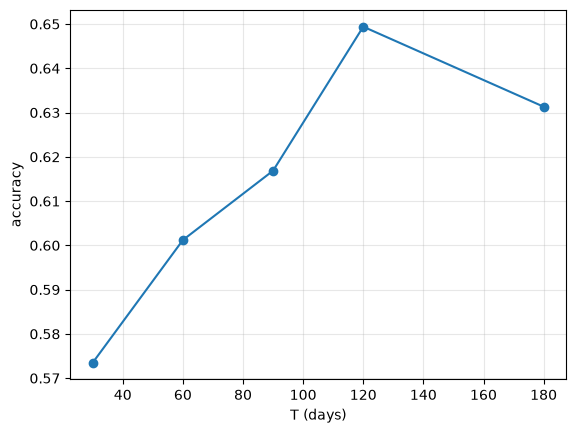

In [4]:
Ts = [30, 60, 90, 120, 180]
accs = [((X_test["days_since_last"] > T).astype(int) == y_test).mean() for T in Ts]
for T, a in zip(Ts, accs):
    print(f"T = {T:>3}: {a:.1%}")
plt.plot(Ts, accs, marker="o"); plt.xlabel("T (days)"); plt.ylabel("accuracy"); plt.grid(alpha=.3); plt.show()

Accuracy peaks around 90–120 days. Below that, too many loyal customers who simply had a quiet summer are flagged; above it, too many real churners are missed.

## Exercise 3

In [5]:
future60 = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-10-31")]
churn60 = (future60.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0) == 0).astype(int)
print(f"90-day window: churn rate {cust['churned'].mean():.1%}, baseline {max(cust['churned'].mean(), 1-cust['churned'].mean()):.1%}")
print(f"60-day window: churn rate {churn60.mean():.1%}, baseline {max(churn60.mean(), 1-churn60.mean()):.1%}")

90-day window: churn rate 43.6%, baseline 56.4%
60-day window: churn rate 55.7%, baseline 55.7%


A shorter window gives customers less time to come back, so more of them are counted as churned. The label depends on a business decision (how long is "gone"?), which is why it must be written down before modelling starts.